# Peran produksi nasional, 2017–2025

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> 17 sektor, workbook RAS.
--> Tahun 2020 ditandai pada sumbu.
--> Pengganda pada gambar ini adalah rasio.
--> Gambar: `01 Data/IO-IRIO-NA/output/`.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "02 Code" / "BKPM" / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "02 Code" / "IO-IRIO-NA"))
import vizstyle as vs
from vizstyle import (
    DATA, OUT, NAVY, TEAL, RUST, GRAY, CREAM, PAPER, SECTOR,
    CMAP_RANK, apply_style, clean, head, save, ink_for, mark_2020, rank_desc,
)

apply_style()
summary = DATA / "IO" / "SUMMARY_IO_MULTIPLIER_ANALYSIS_2017_2025.xlsx"
link = pd.read_excel(summary, sheet_name="Linkages_All")
fac = pd.read_excel(summary, sheet_name="Factor_Mult_All")
spa = pd.read_excel(summary, sheet_name="SPA_Path_Length_All")
inter = pd.read_excel(summary, sheet_name="SPA_Intermediaries_All")

ce_gap = (link.pivot_table(index=["year", "sector_id"], columns="method", values="BL_star")
          .assign(gap=lambda d: (d.ras - d.cross_entropy).abs())["gap"].max())
assert ce_gap == 0
link = link.loc[link.method.eq("ras")].copy()
fac = fac.loc[fac.method.eq("ras")].copy()
spa = spa.loc[spa.method.eq("ras")].copy()
inter = inter.loc[inter.method.eq("ras")].copy()
assert fac.loc[fac.year.eq(2025), "employment_multiplier"].sum() == 0
assert fac.loc[fac.year.eq(2024), "employment_multiplier"].sum() > 0
link["sector_short"] = link.sector_id.map(SECTOR)
fac["sector_short"] = fac.sector_id.map(SECTOR)
print("RAS rows", len(link), "years", sorted(link.year.unique()))

RAS rows 153 years [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## Teks utama


### Gambar 1. Peringkat sektor
--> Peringkat 1 adalah keterkaitan tertinggi atau koefisien nilai tambah tertinggi.
--> Koefisien nilai tambah adalah pangsa nilai tambah langsung dari output sektor itu.


01_sector_ranks.png


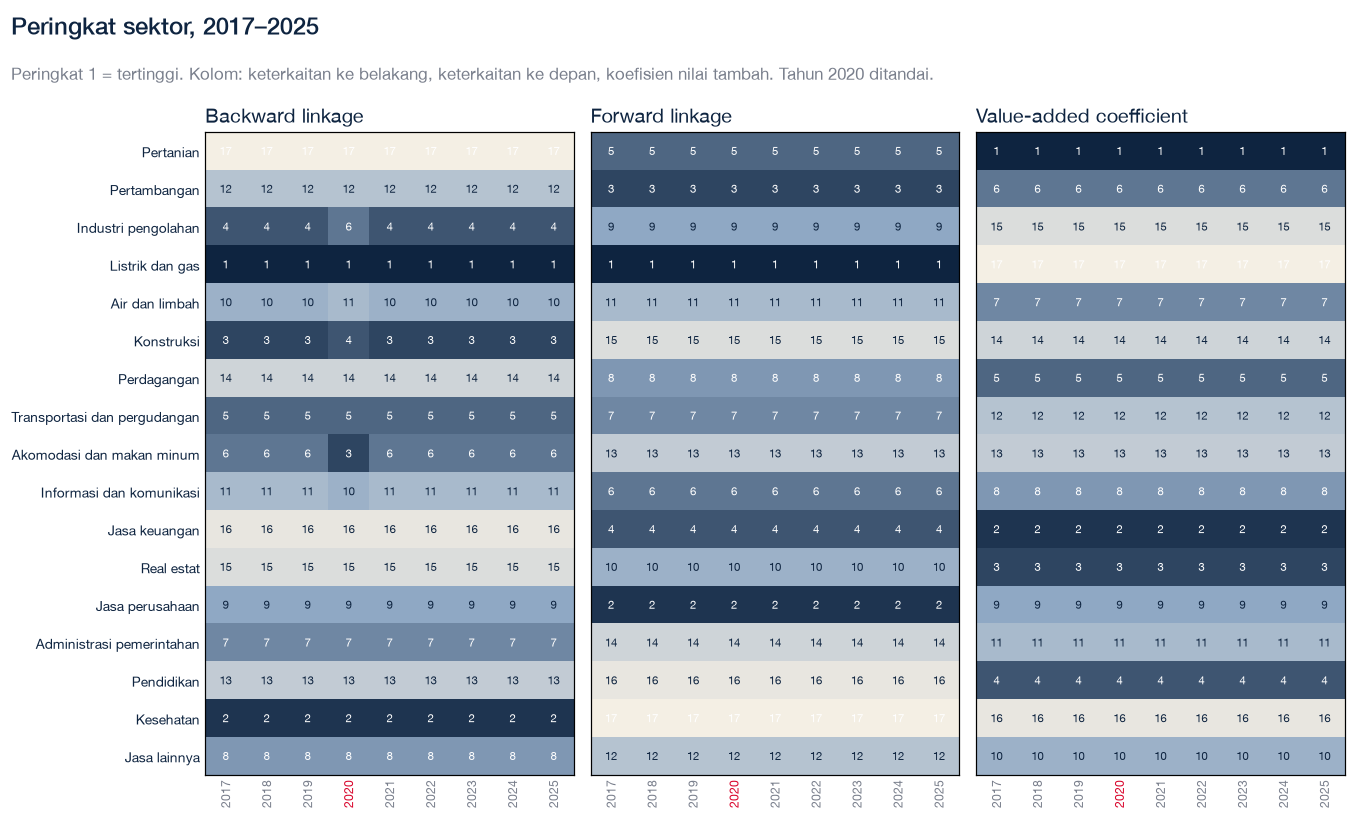

In [2]:
link["r_bl"] = link.groupby("year").BL_star.transform(rank_desc)
link["r_fl"] = link.groupby("year").FL_star.transform(rank_desc)
fac["r_va"] = fac.groupby("year").value_added_coefficient.transform(rank_desc)
order = list(range(1, 18))
labels = [SECTOR[i] for i in order]
cmap = CMAP_RANK.reversed()
panels = [
    (link, "r_bl", "Backward linkage"),
    (link, "r_fl", "Forward linkage"),
    (fac, "r_va", "Value-added coefficient"),
]
fig, axes = plt.subplots(1, 3, figsize=(12.4, 7.6), sharey=True)
for ax, (frame, col, title) in zip(axes, panels):
    wide = frame.pivot(index="sector_id", columns="year", values=col).loc[order]
    im = ax.imshow(wide.to_numpy(), cmap=cmap, vmin=1, vmax=17, aspect="auto")
    for i in range(wide.shape[0]):
        for j, year in enumerate(wide.columns):
            val = int(wide.iloc[i, j])
            ax.text(j, i, str(val), ha="center", va="center", fontsize=7.5,
                    color=ink_for(cmap, val, 1, 17))
    ax.set_xticks(range(len(wide.columns)))
    ax.set_xticklabels(wide.columns, rotation=90, fontsize=8)
    for tick, year in zip(ax.get_xticklabels(), wide.columns):
        if year == 2020:
            tick.set_color(RUST)
    ax.set_title(title, loc="left", fontsize=13)
    ax.tick_params(length=0)
    ax.set_anchor("N")
axes[0].set_yticks(range(len(labels)))
axes[0].set_yticklabels(labels, fontsize=9)
head(fig, "Peringkat sektor, 2017–2025",
     "Peringkat 1 = tertinggi. Kolom: keterkaitan ke belakang, keterkaitan ke depan, koefisien nilai tambah. Tahun 2020 ditandai.")
save(fig, "01_sector_ranks.png")

### Gambar 2. Jalur pengganda output

--> Enam sektor ini adalah puncak urutan keterkaitan dan dua sektor primer. Garis tegak adalah 2020.


01_output_multiplier_paths.png


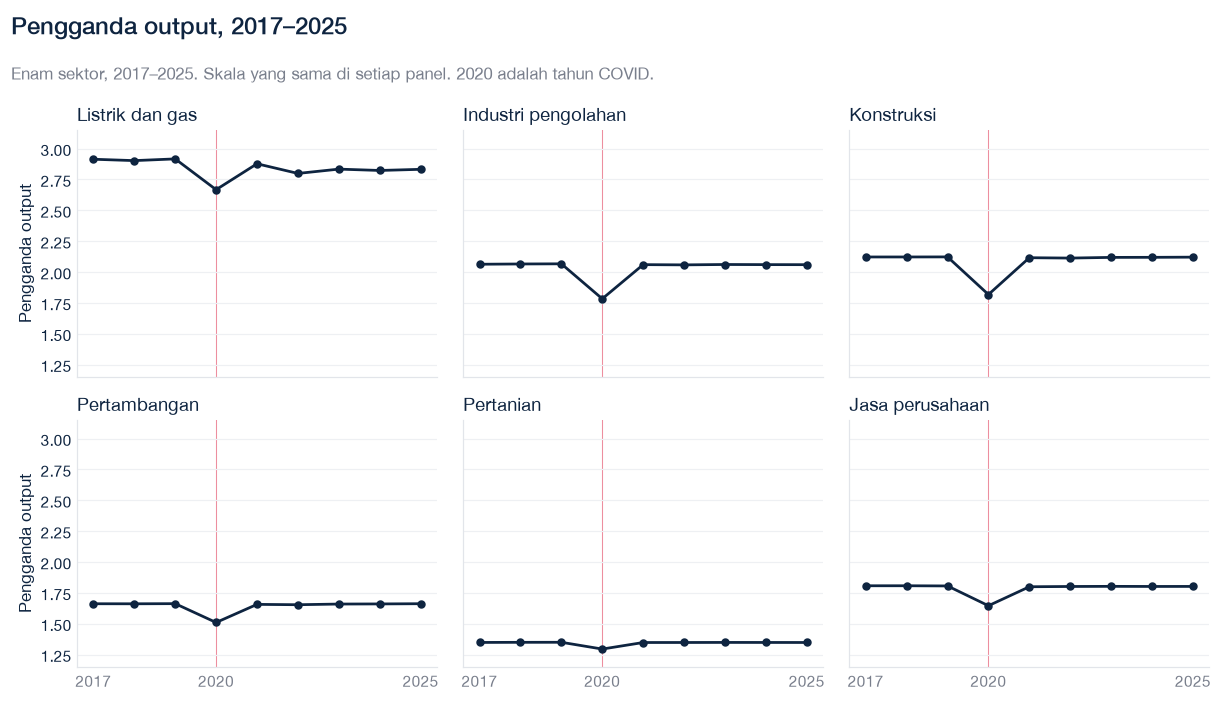

In [3]:
PATHS = [
    "Pengadaan Listrik dan Gas",
    "Industri Pengolahan",
    "Konstruksi",
    "Pertambangan dan Penggalian",
    "Pertanian, Kehutanan, dan Perikanan",
    "Jasa Perusahaan",
]
TITLES = [
    "Listrik dan gas", "Industri pengolahan", "Konstruksi",
    "Pertambangan", "Pertanian", "Jasa perusahaan",
]
fig, axes = plt.subplots(2, 3, figsize=(11.2, 6.4), sharex=True, sharey=True)
for ax, sector, title in zip(axes.ravel(), PATHS, TITLES):
    sub = fac.loc[fac.sector.eq(sector)].sort_values("year")
    mark_2020(ax)
    ax.plot(sub.year, sub.output_multiplier, color=NAVY, marker="o", ms=4.5, lw=1.8)
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xticks([2017, 2020, 2025])
    clean(ax, grid="y")
axes[0, 0].set_ylabel("Pengganda output")
axes[1, 0].set_ylabel("Pengganda output")
axes[0, 0].set_ylim(1.15, 3.15)
head(fig, "Pengganda output, 2017–2025",
     "Enam sektor, 2017–2025. Skala yang sama di setiap panel. 2020 adalah tahun COVID.")
save(fig, "01_output_multiplier_paths.png")

### Gambar 3. Jalur nilai tambah tidak langsung
--> Enam sektor yang sama dan tahun yang sama.


01_indirect_va_paths.png


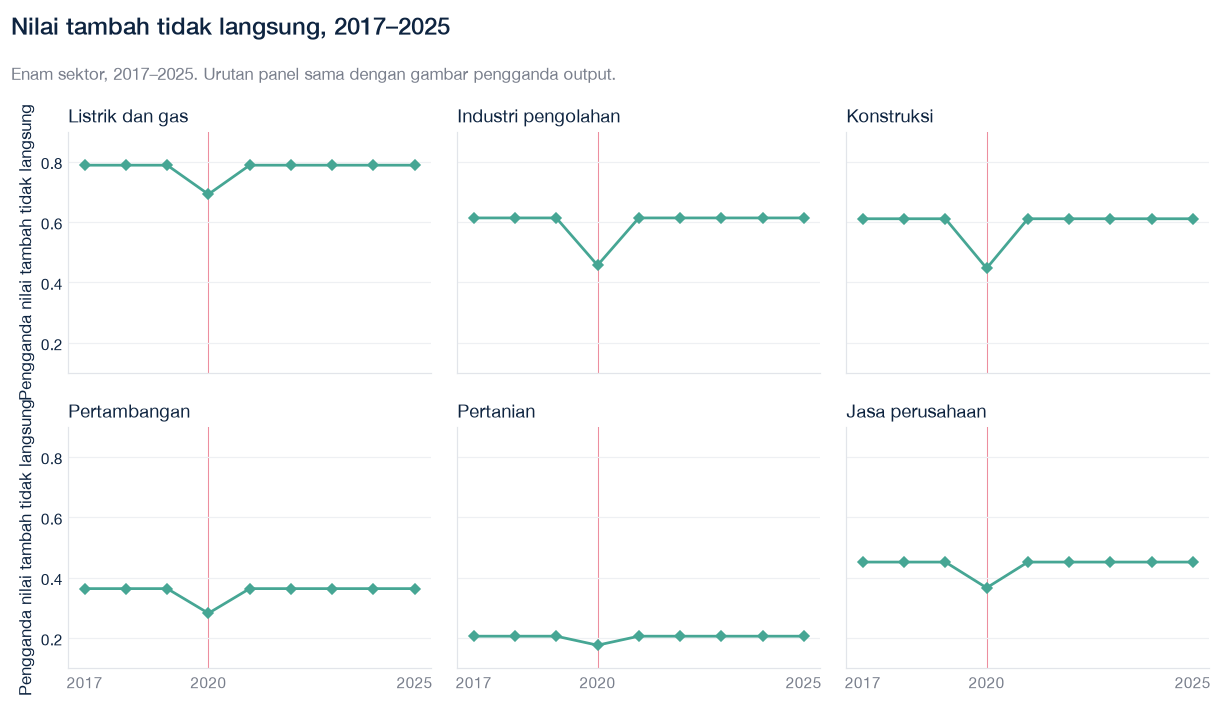

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(11.2, 6.4), sharex=True, sharey=True)
for ax, sector, title in zip(axes.ravel(), PATHS, TITLES):
    sub = fac.loc[fac.sector.eq(sector)].sort_values("year")
    mark_2020(ax)
    ax.plot(sub.year, sub.indirect_va_multiplier, color=TEAL, marker="D", ms=4.5, lw=1.8)
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xticks([2017, 2020, 2025])
    clean(ax, grid="y")
axes[0, 0].set_ylabel("Pengganda nilai tambah tidak langsung")
axes[1, 0].set_ylabel("Pengganda nilai tambah tidak langsung")
axes[0, 0].set_ylim(0.10, 0.90)
head(fig, "Nilai tambah tidak langsung, 2017–2025",
     "Enam sektor, 2017–2025. Urutan panel sama dengan gambar pengganda output.")
save(fig, "01_indirect_va_paths.png")

## Panjang jalur guncangan investasi


### Gambar 4. Panjang jalur
--> Langsung adalah jalur sepanjang nol: sektor yang menerima investasi.
--> Setiap langkah yang lebih panjang adalah satu putaran pembelian antara lagi.
--> Pangsa dihitung dari total Leontief tahun itu.


01_path_length_shares.png


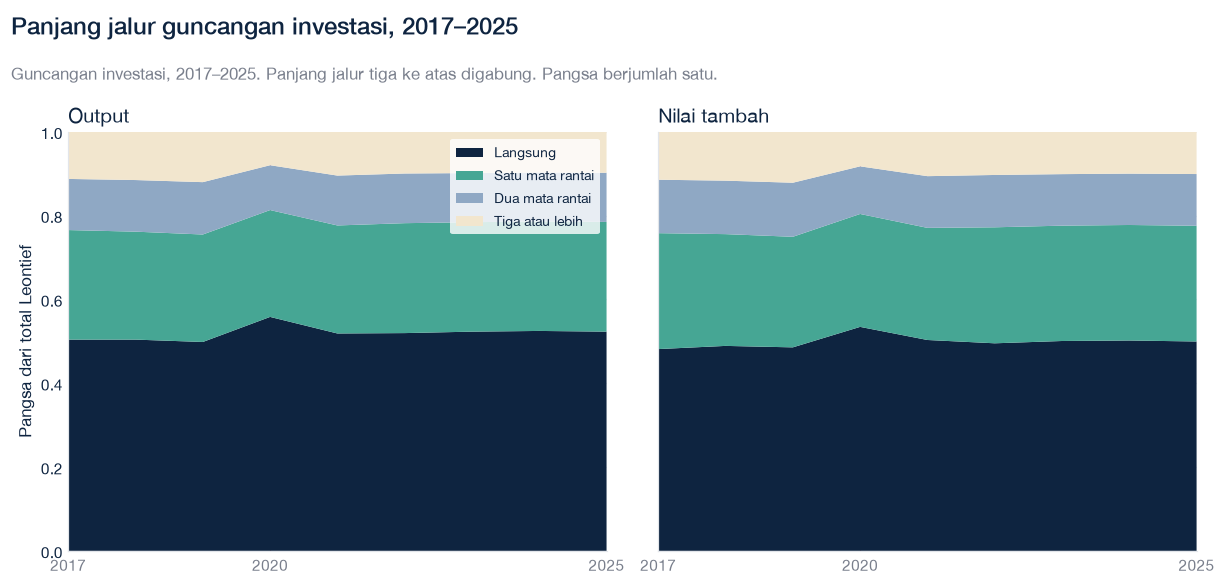

In [5]:
spa = spa.copy()
spa["band"] = np.where(spa.path_length.ge(3), "3 or more", spa.path_length.astype(str))
band_order = ["0", "1", "2", "3 or more"]
band_label = ["Langsung", "Satu mata rantai", "Dua mata rantai", "Tiga atau lebih"]
band_color = [NAVY, TEAL, "#8FA8C4", CREAM]
years = sorted(spa.year.unique())

def band_share(column):
    grouped = (spa.groupby(["year", "band"], as_index=False)[column].sum())
    wide = grouped.pivot(index="year", columns="band", values=column).loc[years, band_order]
    return wide.div(wide.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11.2, 5.2), sharey=True)
for ax, column, title in zip(
    axes,
    ["output_share_percent", "value_added_share_percent"],
    ["Output", "Nilai tambah"],
):
    wide = band_share(column)
    ax.stackplot(wide.index, *[wide[b].to_numpy() for b in band_order],
                 colors=band_color, labels=band_label)
    mark_2020(ax)
    ax.set_xlim(2017, 2025)
    ax.set_ylim(0, 1)
    ax.set_title(title, loc="left", fontsize=13)
    ax.set_xticks([2017, 2020, 2025])
    clean(ax, grid="y")
axes[0].set_ylabel("Pangsa dari total Leontief")
axes[0].legend(frameon=True, facecolor=PAPER, edgecolor="none",
               fontsize=9, loc="upper right")
head(fig, "Panjang jalur guncangan investasi, 2017–2025",
     "Guncangan investasi, 2017–2025. Panjang jalur tiga ke atas digabung. Pangsa berjumlah satu.")
save(fig, "01_path_length_shares.png")

### Gambar 5. Sektor yang membawa nilai tambah tidak langsung
--> Pangsa dihitung dari nilai tambah tidak langsung pada jalur investasi, dan jumlahnya satu.


01_intermediary_shares.png
manufacturing share 0.328 to 0.397


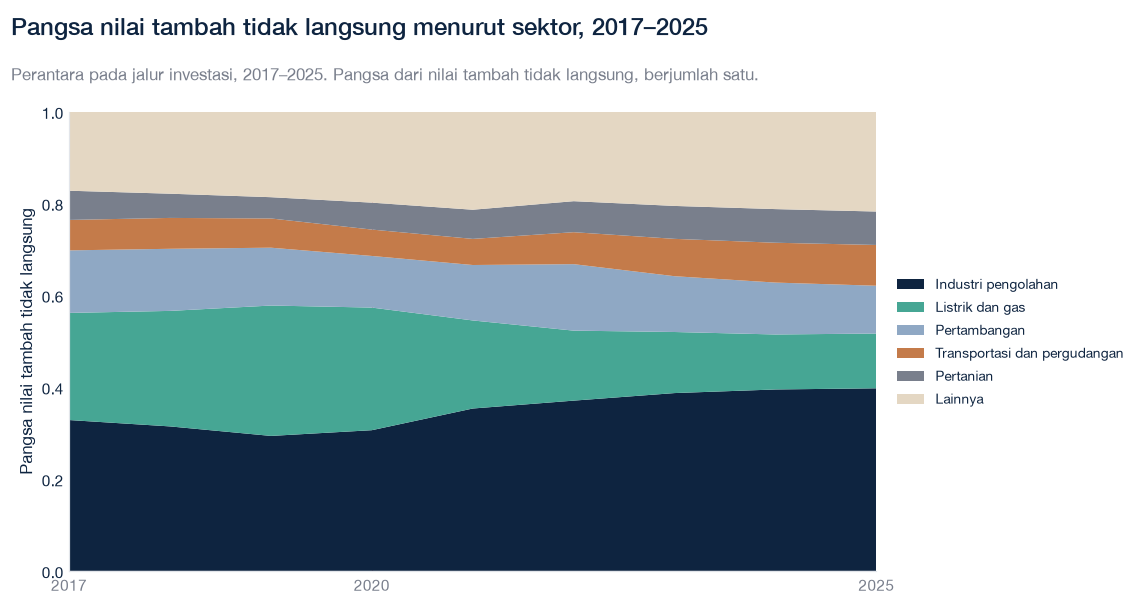

In [6]:
keep = {
    "Industri Pengolahan": "Industri pengolahan",
    "Pengadaan Listrik dan Gas": "Listrik dan gas",
    "Pertambangan dan Penggalian": "Pertambangan",
    "Transportasi dan Pergudangan": "Transportasi dan pergudangan",
    "Pertanian, Kehutanan, dan Perikanan": "Pertanian",
}
order_name = list(keep)
colors = [NAVY, TEAL, "#8FA8C4", "#C47B4A", GRAY, "#E4D7C3"]
piece = inter.copy()
piece["group"] = piece.intermediary_sector.map(keep).fillna("Lainnya")
group_order = list(keep.values()) + ["Lainnya"]
wide = (piece.groupby(["year", "group"]).weighted_value_added_share.sum()
        .unstack("group").loc[years, group_order])
assert np.allclose(wide.sum(axis=1), 1)
fig, ax = plt.subplots(figsize=(10.4, 5.4))
ax.stackplot(wide.index, *[wide[g].to_numpy() for g in group_order],
             colors=colors, labels=group_order)
mark_2020(ax)
ax.set_xlim(2017, 2025)
ax.set_ylim(0, 1)
ax.set_xticks([2017, 2020, 2025])
ax.set_ylabel("Pangsa nilai tambah tidak langsung")
clean(ax, grid="y")
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.01, 0.5))
head(fig, "Pangsa nilai tambah tidak langsung menurut sektor, 2017–2025",
     "Perantara pada jalur investasi, 2017–2025. Pangsa dari nilai tambah tidak langsung, berjumlah satu.")
save(fig, "01_intermediary_shares.png")
manu = wide["Industri pengolahan"]
print("manufacturing share", round(manu.loc[2017], 3), "to", round(manu.loc[2025], 3))

## Lampiran


### Gambar A1. Pengganda output, 2019–2021


01_appendix_covid_return.png


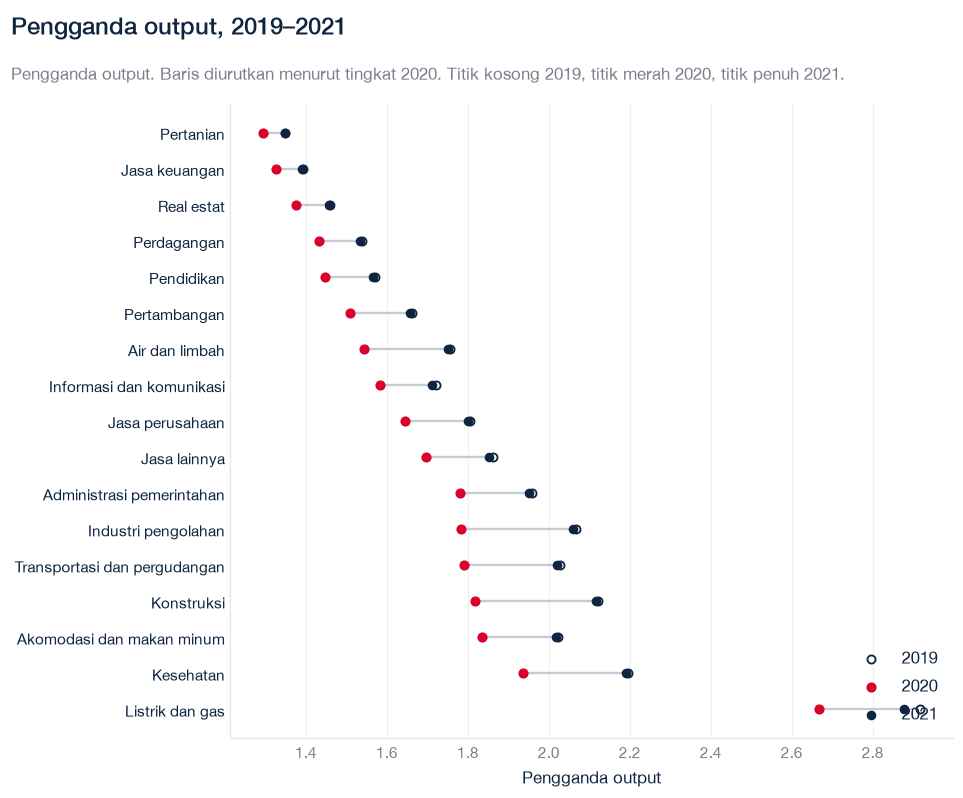

In [7]:
wide = fac.pivot(index="sector_id", columns="year", values="output_multiplier").loc[order]
wide = wide.sort_values(2020)
y = np.arange(len(wide))
fig, ax = plt.subplots(figsize=(8.8, 7.4))
for i, (sid, row) in enumerate(wide.iterrows()):
    ax.plot([row[2019], row[2020], row[2021]], [i, i, i], color="#C5CAD3", lw=1.4, zorder=1)
ax.scatter(wide[2019], y, s=28, facecolor=PAPER, edgecolor=NAVY, linewidth=1.2, zorder=2, label="2019")
ax.scatter(wide[2020], y, s=32, color=RUST, zorder=3, label="2020")
ax.scatter(wide[2021], y, s=28, color=NAVY, zorder=3, label="2021")
ax.set_yticks(y)
ax.set_yticklabels([SECTOR[i] for i in wide.index], fontsize=10)
ax.set_xlabel("Pengganda output")
ax.invert_yaxis()
clean(ax, grid="x")
ax.legend(frameon=False, fontsize=11, loc="lower right")
head(fig, "Pengganda output, 2019–2021",
     "Pengganda output. Baris diurutkan menurut tingkat 2020. Titik kosong 2019, titik merah 2020, titik penuh 2021.")
save(fig, "01_appendix_covid_return.png")

## Penjualan antara menurut sektor
--> Panel di bawah digambar dalam satu putaran, satu sektor pada satu waktu, dan setiap panel menyimpan skala vertikalnya sendiri.
--> Ini penjualan antara nasional.
--> Penjualan antara nasional.


### Gambar 6. Penjualan antara menurut sektor


01_sector_sales_levels.png


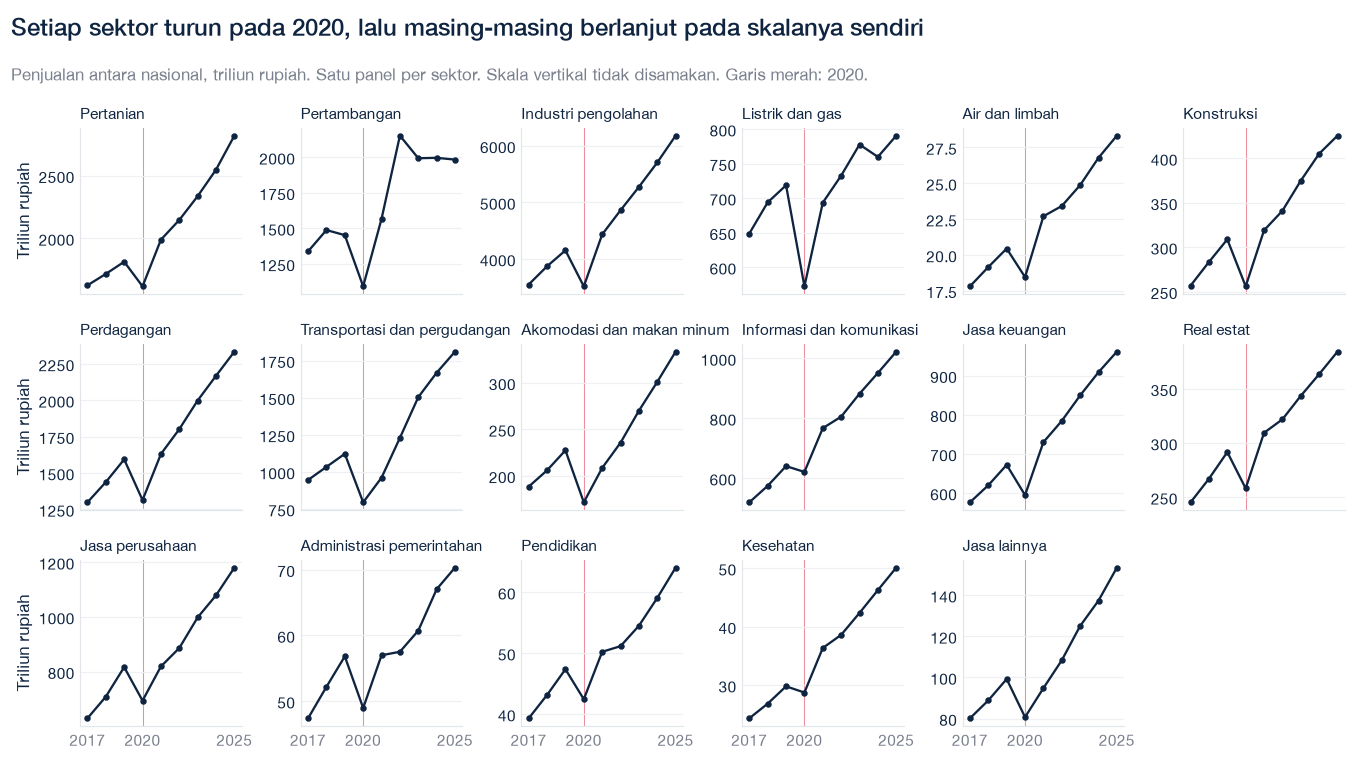

In [8]:
def draw_sales(ax, code):
    sid = vs.SECTOR_ORDER.index(code) + 1
    sub = link.loc[link.sector_id.eq(sid)].sort_values("year")
    mark_2020(ax)
    ax.plot(sub.year, sub.intermediate_sales / vs.TRILLION, color=NAVY, marker="o", ms=3.2, lw=1.5)
    ax.set_xticks([2017, 2020, 2025])

vs.sector_grid(
    vs.SECTOR_ORDER, draw_sales,
    "Setiap sektor turun pada 2020, lalu masing-masing berlanjut pada skalanya sendiri",
    "Penjualan antara nasional, triliun rupiah. Satu panel per sektor. Skala vertikal tidak disamakan. Garis merah: 2020.",
    "01_sector_sales_levels.png",
    ylabel="Triliun rupiah",
)

### Gambar 7. Perubahan pangsa sektoral


01_sector_share_change.png
sector_id
4    -1.55
2    -1.49
12   -0.17
11   -0.12
6    -0.07
14   -0.05
15   -0.02
5    -0.01
16    0.04
9     0.05
17    0.08
1     0.18
13    0.50
3     0.51
7     0.54
10    0.65
8     0.93


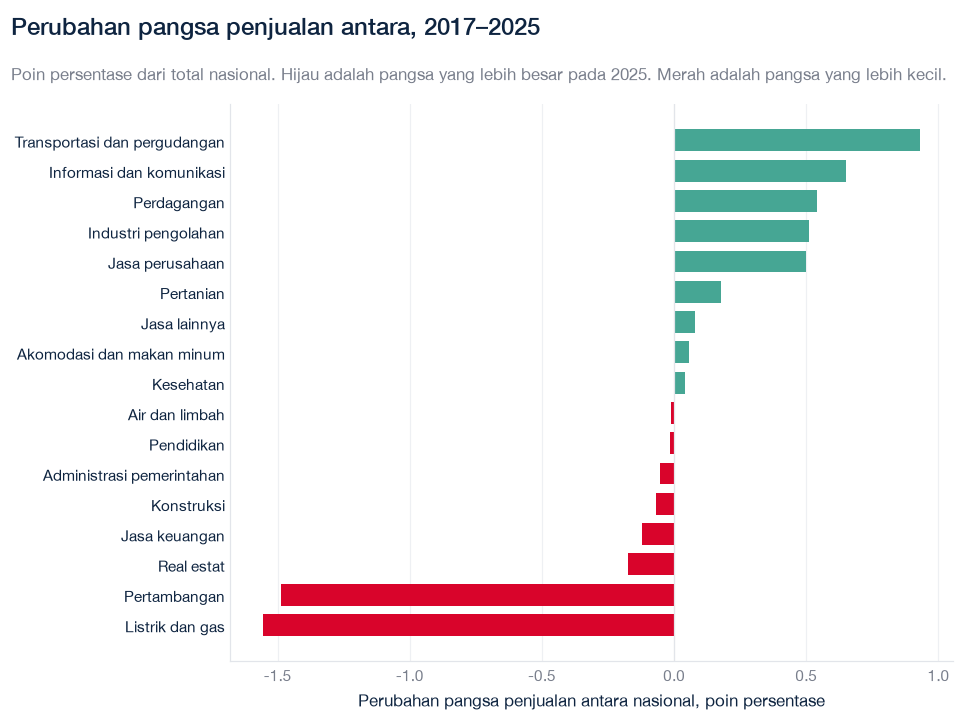

In [9]:
sales = link.pivot(index="year", columns="sector_id", values="intermediate_sales")
share = sales.div(sales.sum(axis=1), axis=0)
delta = ((share.loc[2025] - share.loc[2017]) * 100).sort_values()
fig, ax = plt.subplots(figsize=(8.8, 6.6))
y = np.arange(len(delta))
colors = [TEAL if v >= 0 else RUST for v in delta]
ax.barh(y, delta.to_numpy(), color=colors, height=0.72)
ax.axvline(0, color="#E2E5EA", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels([SECTOR[i] for i in delta.index], fontsize=10)
ax.set_xlabel("Perubahan pangsa penjualan antara nasional, poin persentase")
clean(ax, grid="x")
head(fig, "Perubahan pangsa penjualan antara, 2017–2025",
     "Poin persentase dari total nasional. Hijau adalah pangsa yang lebih besar pada 2025. Merah adalah pangsa yang lebih kecil.")
save(fig, "01_sector_share_change.png")
print(delta.round(2).to_string())